**ARX with news sentiment**

The AR(1) equation was:

$$Inflation_t = c + \phi Inflation_{t-1} + error_t$$

ARX means **autoregressive model with an external input X**. Here, X is news sentiment:

$$Inflation_t = c + \phi Inflation_{t-1} + \beta Sentiment_{t-1} + error_t$$

- $\phi$ measures the relationship with last month's inflation.
- $\beta$ measures whether last month's sentiment adds information after accounting for past inflation.

In [1]:
# Choose one: 'database' or 'csv'
DATA_SOURCE = 'database'

# Keep the same split used in Part 2.
TEST_START = '2017-01-01'

DEFAULT_DB_SERVER = 'lara'
DEFAULT_DB_DATABASE = 'MacroSentimentDB'
DEFAULT_DB_DRIVER = 'ODBC Driver 17 for SQL Server'

In [2]:
from pathlib import Path
import os
import urllib.parse

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

search_locations = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(path for path in search_locations if (path / 'README.md').exists())
CSV_PATH = PROJECT_ROOT / 'data' / 'processed' / 'US' / 'us_macro_2007_2023.csv'

print('Selected source:', DATA_SOURCE)

Selected source: database


**Load CPI and monthly sentiment**

In [3]:
if DATA_SOURCE == 'database':
    from sqlalchemy import create_engine, text

    server = os.getenv('DB_SERVER', DEFAULT_DB_SERVER)
    database = os.getenv('DB_DATABASE', DEFAULT_DB_DATABASE)
    driver = os.getenv('DB_DRIVER', DEFAULT_DB_DRIVER)

    connection_string = (
        f'DRIVER={{{driver}}};SERVER={server};DATABASE={database};'
        'Trusted_Connection=yes;TrustServerCertificate=yes;'
    )
    engine = create_engine(
        f"mssql+pyodbc:///?odbc_connect={urllib.parse.quote_plus(connection_string)}"
    )
    query = text("""
        SELECT month_date, cpi_value, avg_monthly_sentiment
        FROM analytics.Monthly_Region_Wide_View
        WHERE region_code = 'US'
        ORDER BY month_date
    """)
    raw = pd.read_sql(query, engine, parse_dates=['month_date'])
    raw = raw.rename(columns={
        'month_date': 'Date',
        'cpi_value': 'CPI',
        'avg_monthly_sentiment': 'News_Sentiment',
    })
else:
    raw = pd.read_csv(
        CSV_PATH,
        usecols=['Date', 'CPIAUCSL', 'News_Sentiment'],
        parse_dates=['Date'],
    ).rename(columns={'CPIAUCSL': 'CPI'})

raw = raw.sort_values('Date').drop_duplicates('Date').set_index('Date')
raw[['CPI', 'News_Sentiment']] = raw[['CPI', 'News_Sentiment']].apply(
    pd.to_numeric, errors='coerce'
)
print('Rows:', len(raw))
print('Period:', raw.index.min().date(), 'to', raw.index.max().date())
raw.head()

Rows: 204
Period: 2007-01-01 to 2023-12-01


,CPI,News_Sentiment
Date,,
2007-01-01,203.437,NaN
2007-02-01,204.226,NaN
2007-03-01,205.288,NaN
2007-04-01,205.904,NaN
2007-05-01,206.755,NaN


**Create only information known before the forecast month**

In [4]:
data = raw.copy()
data['Inflation_MoM'] = data['CPI'].pct_change(1, fill_method=None) * 100
data['Inflation_Lag1'] = data['Inflation_MoM'].shift(1)
data['Sentiment_Lag1'] = data['News_Sentiment'].shift(1)

model_data = data[[
    'Inflation_MoM', 'Inflation_Lag1', 'Sentiment_Lag1'
]].dropna().copy()

model_data.head(6)

,Inflation_MoM,Inflation_Lag1,Sentiment_Lag1
Date,,,
2007-07-01,0.178060,0.231675,0.273640
2007-08-01,0.030828,0.178060,-0.090171
2007-09-01,0.423755,0.030828,-0.308526
2007-10-01,0.308324,0.423755,-0.392919
2007-11-01,0.785888,0.308324,0.010582
2007-12-01,0.289801,0.785888,-0.439728


**Use the same training and test periods**

In [5]:
test_start = pd.Timestamp(TEST_START)
train = model_data.loc[model_data.index < test_start].copy()
test = model_data.loc[model_data.index >= test_start].copy()

if train.empty or test.empty:
    raise ValueError('The selected TEST_START must leave observations in both periods.')

print('Training period:', train.index.min().date(), 'to', train.index.max().date())
print('Training months:', len(train))
print('Test period:    ', test.index.min().date(), 'to', test.index.max().date())
print('Test months:    ', len(test))

Training period: 2007-07-01 to 2016-12-01
Training months: 114
Test period:     2017-01-01 to 2023-08-01
Test months:     80


**Estimate AR(1) and ARX using OLS**

In [6]:
# AR(1): previous inflation only
X_train_ar1 = sm.add_constant(train[['Inflation_Lag1']], has_constant='add')
ar1_model = sm.OLS(train['Inflation_MoM'], X_train_ar1).fit()

# ARX: previous inflation plus previous sentiment
X_train_arx = sm.add_constant(
    train[['Inflation_Lag1', 'Sentiment_Lag1']], has_constant='add'
)
arx_model = sm.OLS(train['Inflation_MoM'], X_train_arx).fit()

coefficients = pd.DataFrame({
    'AR(1)': [ar1_model.params['const'], ar1_model.params['Inflation_Lag1'], np.nan],
    'ARX': [
        arx_model.params['const'],
        arx_model.params['Inflation_Lag1'],
        arx_model.params['Sentiment_Lag1'],
    ],
}, index=['Constant', 'Previous inflation', 'Previous sentiment'])
coefficients

,AR(1),ARX
Constant,0.067125,0.080275
Previous inflation,0.517665,0.507151
Previous sentiment,NaN,0.047652


In [7]:
beta = arx_model.params['Sentiment_Lag1']
print(f'ARX sentiment coefficient (beta): {beta:.4f}')
print(f'Effect in the equation of a +0.10 sentiment change: {0.10 * beta:.4f}')

ARX sentiment coefficient (beta): 0.0477
Effect in the equation of a +0.10 sentiment change: 0.0048


**Forecast the same test months**

In [8]:
X_test_ar1 = sm.add_constant(test[['Inflation_Lag1']], has_constant='add')
X_test_arx = sm.add_constant(
    test[['Inflation_Lag1', 'Sentiment_Lag1']], has_constant='add'
)

test['Forecast_AR1'] = ar1_model.predict(X_test_ar1)
test['Forecast_ARX'] = arx_model.predict(X_test_arx)

test[[
    'Inflation_MoM', 'Inflation_Lag1', 'Sentiment_Lag1',
    'Forecast_AR1', 'Forecast_ARX'
]].head(10)

,Inflation_MoM,Inflation_Lag1,Sentiment_Lag1,Forecast_AR1,Forecast_ARX
Date,,,,,
2017-01-01,0.404308,0.252452,-0.013130,0.197810,0.207681
2017-02-01,0.159266,0.404308,0.003477,0.276420,0.285486
2017-03-01,-0.046720,0.159266,0.231884,0.149571,0.172097
2017-04-01,0.123415,-0.046720,0.017675,0.042939,0.057423
2017-05-01,-0.077398,0.123415,-0.221750,0.131012,0.132299
2017-06-01,0.065163,-0.077398,-0.135533,0.027059,0.034565
2017-07-01,0.032765,0.065163,-0.309813,0.100857,0.098560
2017-08-01,0.384863,0.032765,-0.056889,0.084086,0.094181
2017-09-01,0.510639,0.384863,-0.037172,0.266354,0.273687


**Compare with one metric: RMSE**

In [9]:
ar1_rmse = np.sqrt(np.mean(
    (test['Inflation_MoM'] - test['Forecast_AR1']) ** 2
))
arx_rmse = np.sqrt(np.mean(
    (test['Inflation_MoM'] - test['Forecast_ARX']) ** 2
))

rmse_comparison = pd.DataFrame({
    'Test RMSE': [ar1_rmse, arx_rmse]
}, index=['AR(1)', 'ARX with lagged sentiment'])
rmse_comparison

,Test RMSE
AR(1),0.272170
ARX with lagged sentiment,0.272643


In [10]:
rmse_change = ar1_rmse - arx_rmse

if rmse_change > 0:
    print(f'ARX improved RMSE by {rmse_change:.4f} percentage points.')
else:
    print(f'ARX did not improve RMSE; it was worse by {-rmse_change:.4f} percentage points.')

ARX did not improve RMSE; it was worse by 0.0005 percentage points.


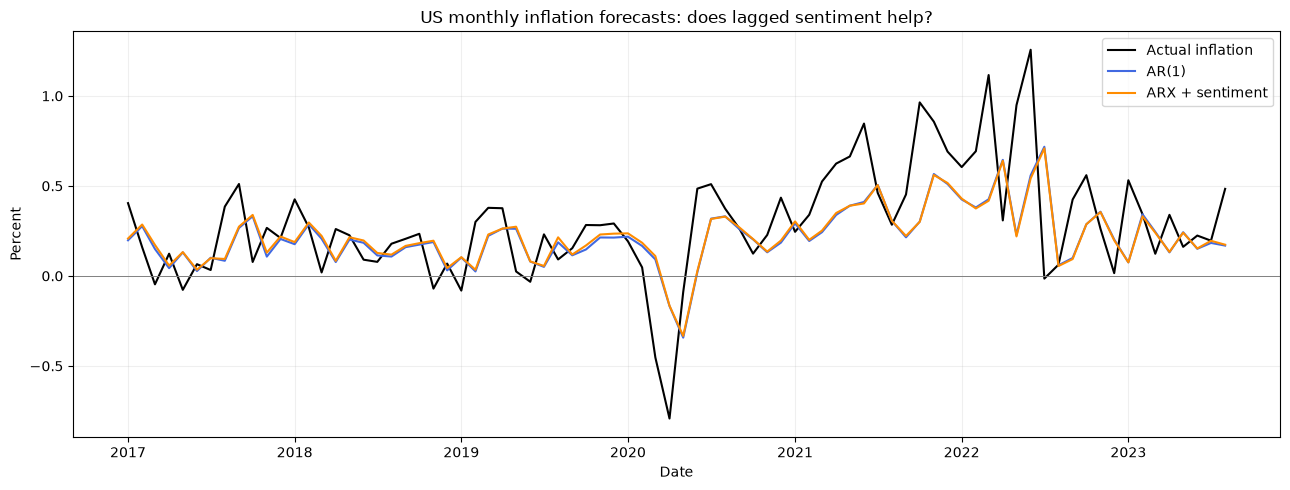

In [11]:
plt.figure(figsize=(13, 5))
plt.plot(test.index, test['Inflation_MoM'], label='Actual inflation', color='black')
plt.plot(test.index, test['Forecast_AR1'], label='AR(1)', color='royalblue')
plt.plot(test.index, test['Forecast_ARX'], label='ARX + sentiment', color='darkorange')
plt.axhline(0, color='gray', linewidth=0.7)
plt.title('US monthly inflation forecasts: does lagged sentiment help?')
plt.ylabel('Percent')
plt.xlabel('Date')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()